#### 04D · PVAR: ¿cuántos armónicos? (n_harm = 1 vs 2)
04C/04D anteriores: gaussianizar las PCs no cambia nada (descartado). El q99 del gradiente sim/hist tiene forma de ola con n_harm = 1: **déficit en transición (≈ 0,75) y exceso en verano (≈ 1,15)** → ciclo estacional quizá demasiado suave.

Prueba (una pieza): el mismo PVAR que producción (p = 10, 6 h, tus 30 PCs) con **n_harm = 1 y 2**, mismas semillas. Métricas de 04C: q99 del gradiente en el sitio por mes, máx. anual, curtosis y std de dpx/dpy.
- La ola se aplana con n_harm = 2 → mejora gratis del PVAR.
- La curtosis no se moverá (sigue siendo gaussiano): para eso hace falta una mezcla de escalas (régimen en Σ).

In [1]:
import time, glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import kurtosis

from utils.pit.piece_wise_marginal import PiecewiseMarginal, to_normal, from_normal
from utils.pit.empirical_marginal import EmpiricalPiece
from utils.tv_var.harmonic_standardizer import HarmonicStandardizer
from utils.tv_var.periodic_var import PeriodicVAR

In [2]:
#### Configuración
FIELD_PATH = "/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/daily_atmospheric/outputs/data/era5_mslp_grad_1985_2026_1deg_hourly.zarr"
PCS_PATH = "outputs/pca/pcs_msl_sel_6h.csv"                 # tus 30 PCs (las que simula el PVAR)
VAR, LAT, LON, TIME = "msl", "latitude", "longitude", "valid_time"
SITIO = (39.6, 3.4)                                         # cerca de Cala Millor
P_VAR = 10                                                  # como producción
N_HARMS = [1, 2]                                            # ← armónicos a comparar (añade 3 si quieres)
N_SIMS_PV, N_ANOS = 5, 40

In [3]:
#### PCs y campo de presión 6-horario 1985–2025
p_mia = pd.read_csv(PCS_PATH, index_col=0, parse_dates=True).loc["1985":"2025"]
ds = xr.open_zarr(FIELD_PATH) if FIELD_PATH.endswith(".zarr") else xr.open_dataset(FIELD_PATH)
ds = ds[VAR].rename({TIME: "time"}).sel(time=slice("1985-01-01", "2025-12-31"))
ds = ds.sel(time=ds.time.dt.hour.isin([0, 6, 12, 18])).transpose("time", LAT, LON)
P = ds.values.astype("float32")
T_, ny, nx = P.shape
tiempo = pd.DatetimeIndex(ds.time.values)
lat_rad = np.deg2rad(np.abs(ds[LAT].values))
p_mia = p_mia.reindex(tiempo)
print(P.shape, "| pasos sin PCs:", int(p_mia.isna().any(axis=1).sum()))
p_mia = p_mia.ffill().bfill()

(59900, 30, 60) | pasos sin PCs: 0


In [4]:
#### Reconstrucción del campo desde tus 30 PCs (regresión B) y gradiente (fórmula de bluemath spatial_gradient)
X = P.reshape(T_, -1)
A = np.c_[np.ones(T_), p_mia.values]
B, *_ = np.linalg.lstsq(A, X, rcond=None)                   # (31, npts)
print(f"varianza del campo explicada por tus 30 PCs: {1 - ((X - A @ B) ** 2).sum() / ((X - X.mean(0)) ** 2).sum():.3f}")
del A

def gradiente(F):
    c = F[:, 1:-1, 1:-1]
    l = np.roll(F, -1, axis=2)[:, 1:-1, 1:-1]; r = np.roll(F, 1, axis=2)[:, 1:-1, 1:-1]
    u = np.roll(F, -1, axis=1)[:, 1:-1, 1:-1]; d = np.roll(F, 1, axis=1)[:, 1:-1, 1:-1]
    cphi = np.cos(lat_rad[1:-1])[None, :, None]
    g = (((c - l) / cphi) ** 2 + ((r - c) / cphi) ** 2) / 2 + ((c - d) ** 2 + (u - c) ** 2) / 2
    return g.reshape(len(F), -1).astype("float32")

iy = np.abs(ds[LAT].values[1:-1] - SITIO[0]).argmin(); ix = np.abs(ds[LON].values[1:-1] - SITIO[1]).argmin()
j_sitio = iy * (nx - 2) + ix

def grad_sitio(pcs_df, paso=4000):
    """PCs → campo reconstruido con B → gradiente al cuadrado en el sitio."""
    V = pcs_df[p_mia.columns].values
    out = []
    for i in range(0, len(V), paso):
        Vi = V[i:i + paso]
        F = (np.c_[np.ones(len(Vi)), Vi] @ B).astype("float32").reshape(-1, ny, nx)
        out.append(gradiente(F)[:, j_sitio])
    return pd.Series(np.concatenate(out), index=pcs_df.index)

#### Diferencias de presión en el sitio (lineales en las PCs)
yy, xx = iy + 1, ix + 1
pts = {"e": (0, 1), "w": (0, -1), "n": (1, 0), "s": (-1, 0)}
Bp = B[:, [(yy + dy) * nx + (xx + dx) for dy, dx in pts.values()]]
cphi_s = np.cos(lat_rad[yy])
def difs(pcs_df):
    V = np.c_[np.ones(len(pcs_df)), pcs_df[p_mia.columns].values] @ Bp
    return pd.DataFrame({"dpx": (V[:, 0] - V[:, 1]) / (2 * cphi_s), "dpy": (V[:, 2] - V[:, 3]) / 2}, index=pcs_df.index)

varianza del campo explicada por tus 30 PCs: 0.959


#### 1. Un PVAR por número de armónicos, mismas semillas

In [5]:
pv, sims = {}, {}
for nh in N_HARMS:
    t = time.time()
    pv[nh] = PeriodicVAR(p=P_VAR, n_harm=nh, freq="6h").fit(p_mia)
    sims[nh] = []
    for i in range(N_SIMS_PV):
        sims[nh].append(pv[nh].simulate(n_years=N_ANOS, seed=100 + i))
    print(f"n_harm = {nh}: ajuste + {N_SIMS_PV} sims ({time.time() - t:.0f} s)", flush=True)

/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model

n_harm = 1: ajuste + 5 sims (7 s)


/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model

n_harm = 2: ajuste + 5 sims (9 s)


#### 2. Métricas de cola (las de 04C)

In [6]:
g_h = grad_sitio(p_mia)
d_hh = difs(p_mia)
q_hist = g_h.groupby(g_h.index.month).quantile(0.99)
am_hist = g_h.groupby(g_h.index.year).max().median()
res_q, res_k, res_s, res_am = {}, {}, {}, {}
for c_ in ["dpx", "dpy"]:
    res_k[(c_, "histórico")] = d_hh[c_].groupby(d_hh.index.month).apply(kurtosis)
for nh in N_HARMS:
    gs = pd.concat([grad_sitio(s_) for s_ in sims[nh]])
    res_q[nh] = gs.groupby(gs.index.month).quantile(0.99) / q_hist
    res_am[nh] = gs.groupby(gs.index.year).max().median() / am_hist
    ds_ = pd.concat([difs(s_) for s_ in sims[nh]])
    for c_ in ["dpx", "dpy"]:
        res_k[(c_, f"n_harm={nh}")] = ds_[c_].groupby(ds_.index.month).apply(kurtosis)
        res_s[(c_, f"n_harm={nh}")] = ds_[c_].groupby(ds_.index.month).std() / d_hh[c_].groupby(d_hh.index.month).std()

tra, ver = [3, 4, 5, 9, 10, 11], [6, 7, 8]
print("q99 del gradiente en el sitio, ratio sim/hist por mes:")
display(pd.DataFrame({f"n_harm={nh}": res_q[nh] for nh in N_HARMS}).T.round(2))
for nh in N_HARMS:
    print(f"n_harm = {nh}: q99 transición {res_q[nh].loc[tra].mean():.2f} | verano {res_q[nh].loc[ver].mean():.2f} | "
          f"máx. anual (mediana) {res_am[nh]:.2f}")
print("\ncurtosis de las diferencias de presión locales:")
display(pd.DataFrame(res_k).T.round(2))
print("std sim/hist de dpx/dpy por mes:")
display(pd.DataFrame(res_s).T.round(2))

q99 del gradiente en el sitio, ratio sim/hist por mes:


,1,2,3,4,5,6,7,8,9,10,11,12
n_harm=1,1.00,1.09,0.82,0.75,0.71,1.07,1.25,1.13,0.76,0.69,0.76,0.91
n_harm=2,0.89,0.99,0.89,0.87,0.76,0.93,1.08,0.97,0.75,0.79,0.86,0.91


n_harm = 1: q99 transición 0.75 | verano 1.15 | máx. anual (mediana) 1.05
n_harm = 2: q99 transición 0.82 | verano 0.99 | máx. anual (mediana) 1.01

curtosis de las diferencias de presión locales:


,,1,2,3,4,5,6,7,8,9,10,11,12
dpx,histórico,0.37,0.75,0.85,0.89,0.78,0.24,0.05,0.35,0.51,0.81,0.52,0.27
dpy,histórico,0.45,0.21,0.30,0.28,0.78,1.00,0.45,0.86,0.93,0.88,0.19,0.30
dpx,n_harm=1,0.00,-0.01,-0.03,0.01,-0.09,-0.00,0.05,0.07,0.01,-0.05,0.16,0.03
dpy,n_harm=1,-0.07,-0.00,0.04,0.03,-0.03,0.01,-0.01,0.06,-0.01,-0.16,-0.07,-0.02
dpx,n_harm=2,0.01,-0.01,-0.06,0.02,-0.04,0.03,0.01,0.07,0.01,-0.04,0.17,-0.00
dpy,n_harm=2,-0.06,-0.00,0.05,0.03,0.04,0.01,0.03,0.06,-0.01,-0.16,-0.10,-0.03


std sim/hist de dpx/dpy por mes:


,,1,2,3,4,5,6,7,8,9,10,11,12
dpx,n_harm=1,1.06,1.08,0.96,0.93,0.97,1.12,1.07,1.06,1.13,0.97,0.88,0.99
dpy,n_harm=1,1.07,1.09,0.94,0.91,0.96,1.07,1.15,1.12,0.97,0.95,0.94,1.00
dpx,n_harm=2,1.00,1.01,0.98,1.00,1.01,1.06,0.96,0.96,1.09,1.02,0.95,1.01
dpy,n_harm=2,1.01,1.04,0.97,0.98,0.98,0.99,1.02,1.04,0.96,1.01,0.99,1.00


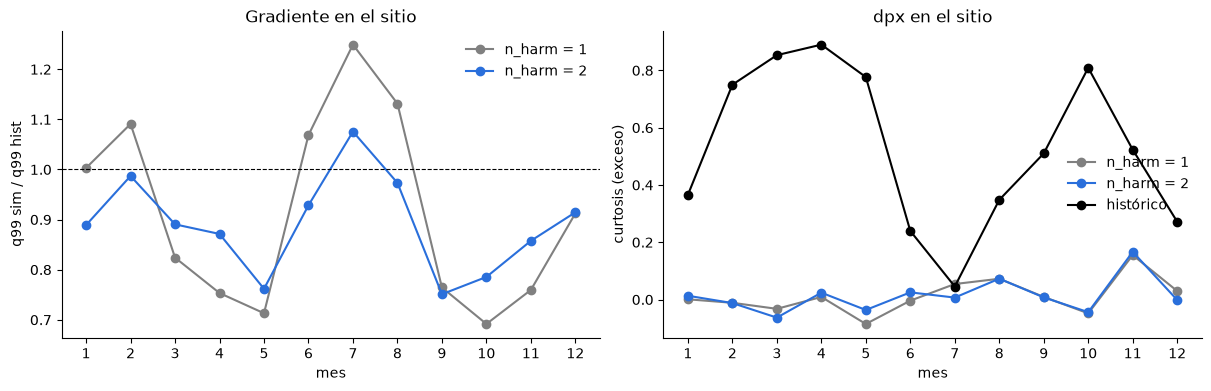

In [7]:
#### Figura
cols = dict(zip(N_HARMS, ["0.5", "#2a6fdb", "#3a9e5f", "#d1495b"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for nh in N_HARMS:
    ax[0].plot(res_q[nh].index, res_q[nh].values, "o-", color=cols[nh], label=f"n_harm = {nh}")
    k_ = res_k[("dpx", f"n_harm={nh}")]
    ax[1].plot(k_.index, k_.values, "o-", color=cols[nh], label=f"n_harm = {nh}")
ax[0].axhline(1, color="k", lw=0.8, ls="--")
k_h = res_k[("dpx", "histórico")]
ax[1].plot(k_h.index, k_h.values, "o-", color="k", label="histórico")
ax[0].set(xlabel="mes", ylabel="q99 sim / q99 hist", title="Gradiente en el sitio", xticks=range(1, 13))
ax[1].set(xlabel="mes", ylabel="curtosis (exceso)", title="dpx en el sitio", xticks=range(1, 13))
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.legend(frameon=False)
plt.show()

#### Cómo leerlo
- **Ola más plana con n_harm = 2** (transición hacia 1, verano hacia 1) → la forma estacional era de los armónicos; pasar n_harm = 2 a producción y comprobar con 08 + 09B si bajan los −29 % de temporales.
- **Transición sigue en ≈ 0,75** → el déficit es de curtosis (mezcla de escalas: régimen en Σ, DWT con Σ por tipo o GARCH).
- La curtosis (derecha) seguirá ≈ 0 con cualquier n_harm: es lo esperado.